# 02 - Profiling, duplicate customers and EDA (DS, Days 3-5)

**Goal:** (A) profile the categorical columns and find the messy values, (B) find duplicate customers and build a
`duplicate -> survivor` mapping table, (C) run the first EDA and check it against what the data README says to expect.

**Rules for this notebook**
- Never read `_restricted/`. The answer key is only for scoring the final clustering.
- Duplicates are found from the customer's own fields, not from the answer key.
- Cells that depend on column names I could not see (marked **CONFIG**) print what they found. Check the output before trusting the result.

In [1]:
%pip install -q duckdb pandas pyarrow matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 0. Setup

In [2]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import sys
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path.cwd()))            # so `cleaning_maps.py` (same folder) can be imported
from cleaning_maps import LEAD_SOURCE_MAP, COUNTRY_MAP

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 60)

ROOT = Path.cwd().parent                      # veltrix-segmentation_A/
base = ROOT / "data" / "raw" / "veltrix_medium"
OUT = ROOT / "notebooks" / "outputs"
OUT.mkdir(exist_ok=True)
assert base.exists(), f"Data folder not found: {base}"

SMALL = ["agents", "campaigns", "campaign_responses", "customers", "interactions", "leads",
         "locations", "payments", "properties", "site_visits", "transactions"]
BIG = ["web_sessions", "property_views"]       # folders of part files: query with DuckDB, don't load into pandas

tables = {t: pd.read_parquet(base / f"{t}.parquet") for t in SMALL}

con = duckdb.connect()
D = base.as_posix()
for t in SMALL:
    con.execute(f"CREATE OR REPLACE VIEW {t} AS SELECT * FROM read_parquet('{D}/{t}.parquet')")
for t in BIG:
    con.execute(f"CREATE OR REPLACE VIEW {t} AS SELECT * FROM read_parquet('{D}/{t}/*.parquet')")

checks = {}   # filled as we go, compared with the README in section D
{t: df.shape for t, df in tables.items()}

{'agents': (300, 6),
 'campaigns': (270, 10),
 'campaign_responses': (808953, 5),
 'customers': (102000, 19),
 'interactions': (532789, 8),
 'leads': (95804, 11),
 'locations': (36, 9),
 'payments': (106199, 10),
 'properties': (16667, 19),
 'site_visits': (233593, 6),
 'transactions': (16665, 14)}

## A. Profile the categorical columns
First a scan of every small table: which columns are categorical, how many distinct values, how much is missing.

In [3]:
from pandas.api.types import is_numeric_dtype, is_datetime64_any_dtype, is_bool_dtype

def profile_categoricals(df, max_card=60):
    rows = []
    for c in df.columns:
        s = df[c]
        if is_datetime64_any_dtype(s) or (is_numeric_dtype(s) and not is_bool_dtype(s)):
            continue
        nun = s.nunique(dropna=True)
        top = s.value_counts(dropna=True).head(4)
        rows.append({
            "column": c, "dtype": str(s.dtype), "n_unique": nun,
            "null_%": round(s.isna().mean() * 100, 1),
            "top_values": ", ".join(f"{k} ({v})" for k, v in top.items()) if nun <= max_card else "(high cardinality)",
        })
    return pd.DataFrame(rows)

for name in ["customers", "leads", "agents", "campaigns", "properties", "locations", "transactions", "payments", "interactions", "site_visits"]:
    print(f"\n=== {name} {tables[name].shape} ===")
    display(profile_categoricals(tables[name]))


=== customers (102000, 19) ===


,column,dtype,n_unique,null_%,top_values
0,customer_id,str,102000,0.0,(high cardinality)
1,email_sha256,str,100897,0.0,(high cardinality)
2,phone_sha256,str,72356,28.4,(high cardinality)
3,customer_type,str,3,0.0,"Individual (90844), Limited company (SPV) (8443), Corpor..."
4,gender,str,3,10.9,"Female (44995), Male (41691), Not stated (4158)"
5,age_band,str,6,27.5,"25-34 (24263), 35-44 (19426), 45-54 (9941), 18-24 (8334)"
6,occupation_sector,str,16,26.8,"Technology (9357), Finance (8687), Healthcare (8124), Bu..."
7,country_of_residence,str,26,0.0,"United Kingdom (64406), UK (14124), England (7435), Grea..."
8,is_overseas,bool,2,0.0,"False (92404), True (9596)"
9,uk_region_of_residence,str,11,9.4,"South East (13249), London (13238), North West (12425), ..."



=== leads (95804, 11) ===


,column,dtype,n_unique,null_%,top_values
0,lead_id,str,95804,0.0,(high cardinality)
1,customer_id,str,61030,0.0,(high cardinality)
2,agent_id,str,300,0.0,(high cardinality)
3,lead_source,str,28,0.0,"Rightmove (22202), Zoopla (11329), Veltrix website (1084..."
4,campaign_id,string,270,67.2,(high cardinality)
5,intent,str,2,0.0,"Buy (78633), Rent (17171)"
6,lead_stage,str,7,0.0,"Lost (74759), Won (16665), Viewing (1119), Qualified (1007)"
7,lost_reason,str,11,22.0,"Outbid (12547), No response (11832), Bought elsewhere (1..."
8,closed_date,object,1364,4.6,(high cardinality)
9,converted,bool,2,0.0,"False (79139), True (16665)"



=== agents (300, 6) ===


,column,dtype,n_unique,null_%,top_values
0,agent_id,str,300,0.0,(high cardinality)
1,team,str,26,0.0,"London Sales (25), West Midlands Sales (21), South West ..."
2,branch,str,36,0.0,"London (Canary Wharf) (39), Manchester (20), Birmingham ..."
3,seniority,str,3,0.0,"Mid (120), Junior (101), Senior (79)"
4,hire_date,object,294,0.0,(high cardinality)
5,propertymark_qualified,bool,2,0.0,"True (158), False (142)"


... (10 outputs left out)


=== interactions (532789, 8) ===


,column,dtype,n_unique,null_%,top_values
0,interaction_id,str,532789,0.0,(high cardinality)
1,lead_id,str,95804,0.0,(high cardinality)
2,agent_id,str,300,0.0,(high cardinality)
3,channel,str,6,0.0,"Phone (174970), Email (151588), WhatsApp (124831), Live ..."
4,direction,str,2,0.0,"Inbound (292997), Outbound (239792)"
5,topic,str,15,0.0,"Viewing arrangements (84036), Mortgage and finance (6764..."



=== site_visits (233593, 6) ===


,column,dtype,n_unique,null_%,top_values
0,visit_id,str,233593,0.0,(high cardinality)
1,lead_id,str,83766,0.0,(high cardinality)
2,property_id,str,15828,0.0,(high cardinality)
3,visit_type,str,4,0.0,"In person (166554), Virtual (34241), Open house (20797),..."
4,visit_date,object,1369,0.0,(high cardinality)
5,outcome,str,5,0.0,"Not interested (86951), Interested (76086), Second viewi..."


### A1. Lead source spellings
The README says there are 14 inconsistent spellings. The cell below lists every raw value and groups the ones that only differ by case,
spaces or punctuation (e.g. `Right Move` and `rightmove`). Values like `OTM` or `FB` will not group automatically. Those need a manual map.

In [4]:
def norm_key(x):
    return re.sub(r"[^a-z0-9]", "", str(x).lower())

def variant_groups(s):
    vc = s.value_counts(dropna=True)
    g = pd.DataFrame({"value": vc.index, "n": vc.values})
    g["key"] = g["value"].map(norm_key)
    multi = g.groupby("key").filter(lambda d: len(d) > 1).sort_values(["key", "n"], ascending=[True, False])
    return g, multi

raw_sources, source_variants = variant_groups(tables["leads"]["lead_source"])
print(f"{len(raw_sources)} distinct raw lead_source values")
display(raw_sources)
print("\nValues that collapse to the same key after lower-casing and removing punctuation:")
display(source_variants)

28 distinct raw lead_source values


,value,n,key
0,Rightmove,22202,rightmove
1,Zoopla,11329,zoopla
2,Veltrix website,10845,veltrixwebsite
3,Referral,5972,referral
4,Google Ads,5695,googleads
5,Email newsletter,5622,emailnewsletter
6,Facebook,4784,facebook
7,TikTok,4481,tiktok
8,OnTheMarket,4005,onthemarket
9,Instagram,3809,instagram



Values that collapse to the same key after lower-casing and removing punctuation:


,value,n,key
4,Google Ads,5695,googleads
24,google ads,367,googleads
8,OnTheMarket,4005,onthemarket
26,On The Market,272,onthemarket
0,Rightmove,22202,rightmove
14,Right Move,1024,rightmove
15,RightMove,1012,rightmove
16,rightmove,1005,rightmove
1,Zoopla,11329,zoopla
17,zoopla,771,zoopla


### A1b. Apply the agreed lead-source map (`cleaning_maps.py`)
28 raw spellings map to 14 clean channels. `Google` and `Website` are assumptions (see the comments in `cleaning_maps.py`). Confirm them with the DA team.

In [5]:
raw_vals = set(tables["leads"]["lead_source"].dropna().unique())
print("Raw values missing from LEAD_SOURCE_MAP:", sorted(raw_vals - set(LEAD_SOURCE_MAP)) or "none")
print("Map keys not present in the data:", sorted(set(LEAD_SOURCE_MAP) - raw_vals) or "none")
clean_src = tables["leads"]["lead_source"].map(LEAD_SOURCE_MAP)
print(f"\n{clean_src.nunique()} clean channels:")
print(clean_src.value_counts().to_string())

Raw values missing from LEAD_SOURCE_MAP: none
Map keys not present in the data: none

14 clean channels:
lead_source
Rightmove                 25243
Zoopla                    12841
Veltrix website           12275
Google Ads                 6425
Referral                   5972
Email newsletter           5622
Facebook                   5413
OnTheMarket                4532
TikTok                     4481
Instagram                  4351
Branch walk-in             3008
Overseas agent partner     2575
Relocation partner         1943
WeChat                     1123


### A2. Country labels

In [6]:
country_cols = {t: [c for c in df.columns if re.search("country", c, re.I)] for t, df in tables.items()}
country_cols = {t: c for t, c in country_cols.items() if c}
print("Tables with a country column:", country_cols)
for t, cols in country_cols.items():
    for c in cols:
        print(f"\n--- {t}.{c} ---")
        print(tables[t][c].value_counts(dropna=False).head(30).to_string())

print("\n--- web_sessions.ip_country (top 20) ---")
display(con.sql("SELECT ip_country, COUNT(*) AS n FROM web_sessions GROUP BY 1 ORDER BY 2 DESC LIMIT 20").df())

Tables with a country column: {'customers': ['country_of_residence'], 'locations': ['country']}

--- customers.country_of_residence ---
country_of_residence
United Kingdom          64406
UK                      14124
England                  7435
Great Britain            3664
U.K.                     2775
Hong Kong                1306
United Arab Emirates     1064
India                     863
Nigeria                   787
Singapore                 771
China                     711
United States             702
Canada                    545
UAE                       480
USA                       399
HK                        358
Malaysia                  327
Saudi Arabia              285
Qatar                     244
Hong Kong SAR             198
US                        129
Mainland China            100
U.A.E.                     94
PRC                        92
SG                         88
KSA                        53

--- locations.country ---
country
England     31
Scotland     

,ip_country,n
0,GB,1818777
1,HK,27575
2,AE,24938
3,US,22166
4,SG,18545
5,NG,14760
6,CN,13884
7,IN,11402
8,CA,8809
9,MY,7556


### A3. Budgets: missing values and typos
README: 20-70% of budgets are missing depending on persona, and about 0.4% are typos (an extra zero, a dropped digit).
The purchase budget and the monthly rent budget are separate columns, so each is compared with its own median. Values far below or far above it are suspect. Check the examples before treating any flag as fact.

In [7]:
cust = tables["customers"]
budget_cols = [c for c in cust.columns if re.search("budget", c, re.I) and is_numeric_dtype(cust[c])]
print("Budget columns:", budget_cols)

for c in budget_cols:
    s = cust[c].astype("float64")
    med = s.median()
    ratio = s / med
    print(f"\n--- {c} ---")
    print(f"missing: {s.isna().mean()*100:.1f}%   median: {med:,.0f}")
    print(s.describe(percentiles=[.01, .05, .5, .95, .99]).round(0).to_string())
    print("\nHow many values fall in each range (look for a cluster of implausibly small values):")
    print(pd.cut(s.dropna(), [0, 1_000, 10_000, 50_000, 100_000, 1_000_000, 2_000_000, np.inf], right=False).value_counts().sort_index().to_string())
    small, big = s[ratio <= 0.15], s[ratio >= 5]
    pct = (len(small) + len(big)) / s.notna().sum() * 100
    print(f"\nfar below typical (<=0.15x median): {len(small)} | far above (>=5x median): {len(big)} | together {pct:.2f}% of non-missing (README: about 0.4% are typos)")
    display(pd.concat([small.sort_values().head(8), big.sort_values().tail(8)]).to_frame(c).assign(ratio_to_median=lambda d: (d[c] / med).round(3)))
    checks[f"typo_rate_{c}_%"] = round(pct, 2)

Budget columns: ['stated_budget_gbp', 'stated_rent_budget_pcm_gbp']

--- stated_budget_gbp ---
missing: 51.0%   median: 305,000
count       50014.0
mean       372166.0
std        276508.0
min           110.0
1%         100000.0
5%         140000.0
50%        305000.0
95%        795000.0
99%       1190000.0
max      11650000.0

How many values fall in each range (look for a cluster of implausibly small values):
stated_budget_gbp
[0.0, 1000.0)                64
[1000.0, 10000.0)             2
[10000.0, 50000.0)            0
[50000.0, 100000.0)         307
[100000.0, 1000000.0)     48642
[1000000.0, 2000000.0)      925
[2000000.0, inf)             74

far below typical (<=0.15x median): 66 | far above (>=5x median): 161 | together 0.45% of non-missing (README: about 0.4% are typos)


,stated_budget_gbp,ratio_to_median
21571,110.0,0.000
41010,115.0,0.000
99043,120.0,0.000
36550,155.0,0.001
68711,160.0,0.001
95528,160.0,0.001
9483,165.0,0.001
56940,180.0,0.001
95931,8000000.0,26.230
63459,8450000.0,27.705



--- stated_rent_budget_pcm_gbp ---
missing: 87.2%   median: 1,500
count    13061.0
mean      1838.0
std       1467.0
min        450.0
1%         700.0
5%         850.0
50%       1500.0
95%       3750.0
99%       5650.0
max      53400.0

How many values fall in each range (look for a cluster of implausibly small values):
stated_rent_budget_pcm_gbp
[0.0, 1000.0)              1447
[1000.0, 10000.0)         11567
[10000.0, 50000.0)           46
[50000.0, 100000.0)           1
[100000.0, 1000000.0)         0
[1000000.0, 2000000.0)        0
[2000000.0, inf)              0

far below typical (<=0.15x median): 0 | far above (>=5x median): 54 | together 0.41% of non-missing (README: about 0.4% are typos)


,stated_rent_budget_pcm_gbp,ratio_to_median
97432,23400.0,15.600
65215,25200.0,16.800
17653,27000.0,18.000
94402,30000.0,20.000
41089,30000.0,20.000
66288,34200.0,22.800
31082,41000.0,27.333
35954,53400.0,35.600


### A4. Missing values in `customers` (README: 18% age_band, 25% occupation_sector ...)

In [8]:
miss = (cust.isna().mean() * 100).round(1).sort_values(ascending=False).to_frame("missing_%")
display(miss[miss["missing_%"] > 0])

,missing_%
stated_rent_budget_pcm_gbp,87.2
stated_budget_gbp,51.0
phone_sha256,28.4
age_band,27.5
occupation_sector,26.8
gender,10.9
uk_region_of_residence,9.4


### A5. Web sessions: device, traffic source, anonymous share

In [9]:
for col in ["device", "traffic_source"]:
    print(f"\n--- {col} ---")
    display(con.sql(f"SELECT {col}, COUNT(*) AS n, ROUND(100.0*COUNT(*)/SUM(COUNT(*)) OVER (), 1) AS pct FROM web_sessions GROUP BY 1 ORDER BY 2 DESC").df())

anon = con.sql("SELECT ROUND(100.0*AVG(CASE WHEN customer_id IS NULL THEN 1 ELSE 0 END), 1) AS anon_pct FROM web_sessions").df().iloc[0, 0]
print(f"Anonymous sessions (no customer_id): {anon}%   (README: about 25%)")
checks["anonymous_sessions_%"] = anon


--- device ---


,device,n,pct
0,Mobile,1231292,61.5
1,Desktop,592914,29.6
2,Tablet,179254,8.9



--- traffic_source ---


,traffic_source,n,pct
0,Property portal referral,475337,23.7
1,Organic search,464571,23.2
2,Paid social,260871,13.0
3,Direct,248986,12.4
4,Organic social,185291,9.2
5,Paid search,158912,7.9
6,Email,155094,7.7
7,Referral partner,54398,2.7


Anonymous sessions (no customer_id): 25.0%   (README: about 25%)


## B. Duplicate customers
README: about 2% of customers are duplicates. Each duplicate has its own `customer_id`, slightly different answers, and one extra lead.
`customers` has 102,000 rows for 100,000 real people, so I expect about 2,000 duplicate records.

**What the data lets us use:** emails and phones are stored only as SHA-256 hashes, and there are no name or postcode columns.
A hash can only be compared for **exact equality**, so it must not be cleaned, lower-cased or stripped.
Matching has to rest on shared hashes plus agreement on the profile fields.

### B1. CONFIG: columns used for matching

In [10]:
ID_COL, EMAIL, PHONE, DATE_COL = "customer_id", "email_sha256", "phone_sha256", "first_contact_date"
ATTRS = ["customer_type", "gender", "country_of_residence", "uk_region_of_residence", "primary_intent", "preferred_currency"]

missing_cols = [c for c in [ID_COL, EMAIL, PHONE, DATE_COL] + ATTRS if c not in cust.columns]
assert not missing_cols, f"Columns not found in customers: {missing_cols}"

c2 = cust[[ID_COL, EMAIL, PHONE, DATE_COL] + ATTRS].copy()
c2[DATE_COL] = pd.to_datetime(c2[DATE_COL], errors="coerce")
for col in (EMAIL, PHONE):
    c2[col] = c2[col].replace("", pd.NA)

n = len(c2)
print(f"rows: {n}")
print(f"email hash: {c2[EMAIL].isna().mean()*100:.1f}% missing, {n - c2[EMAIL].nunique(dropna=True) - c2[EMAIL].isna().sum()} extra rows sharing a hash")
print(f"phone hash: {c2[PHONE].isna().mean()*100:.1f}% missing, {c2[PHONE].notna().sum() - c2[PHONE].nunique(dropna=True)} extra rows sharing a hash")

rows: 102000
email hash: 0.0% missing, 1103 extra rows sharing a hash
phone hash: 28.4% missing, 726 extra rows sharing a hash


### B2. Find candidate pairs that share a hash
Blocks bigger than 5 are skipped, because a hash shared by many records is more likely a shared mailbox or number than a duplicate.

In [11]:
def shared_pairs(col, max_block=5):
    k = c2[[ID_COL, col]].dropna()
    size = k.groupby(col)[ID_COL].transform("size")
    skipped = int((size > max_block).sum())
    pairs = []
    for _, g in k[(size >= 2) & (size <= max_block)].groupby(col)[ID_COL]:
        ids = g.tolist()
        for i in range(len(ids)):
            for j in range(i + 1, len(ids)):
                pairs.append((ids[i], ids[j]))
    return pairs, skipped

email_pairs, sk_e = shared_pairs(EMAIL)
phone_pairs, sk_p = shared_pairs(PHONE)
print(f"pairs sharing an email hash: {len(email_pairs)}   (records in oversized blocks skipped: {sk_e})")
print(f"pairs sharing a phone hash : {len(phone_pairs)}   (records in oversized blocks skipped: {sk_p})")

A = c2.set_index(ID_COL)

def pair_table(pairs):
    p = pd.DataFrame(pairs, columns=["a", "b"])
    L = A.loc[p["a"], ATTRS].astype(object).fillna("<L>").reset_index(drop=True)
    R = A.loc[p["b"], ATTRS].astype(object).fillna("<R>").reset_index(drop=True)
    p["attr_agree"] = (L.values == R.values).sum(axis=1)
    da = A.loc[p["a"], DATE_COL].reset_index(drop=True)
    db = A.loc[p["b"], DATE_COL].reset_index(drop=True)
    p["days_apart"] = (da - db).abs().dt.days
    return p

email_tbl = pair_table(email_pairs)
phone_tbl = pair_table(phone_pairs)

pairs sharing an email hash: 1103   (records in oversized blocks skipped: 0)
pairs sharing a phone hash : 726   (records in oversized blocks skipped: 0)


### B3. Do the matched pairs look like real duplicates?
Compare how many of the 6 profile fields agree for the matched pairs against 20,000 **random** pairs.
Random pairs agree on a few fields by chance (most customers are UK individuals). Real duplicates should agree on far more. Do not expect close first-contact dates: the matched pairs in your own data were created 8 to 108 days apart.

In [12]:
rng = np.random.default_rng(0)
ids = A.index.to_numpy()
rnd = pd.DataFrame({"a": rng.choice(ids, 20000), "b": rng.choice(ids, 20000)})
rnd = rnd[rnd["a"] != rnd["b"]]
rand_tbl = pair_table(list(zip(rnd["a"], rnd["b"])))

cmp = pd.DataFrame({
    "email-hash pairs": email_tbl["attr_agree"].value_counts(normalize=True).sort_index(),
    "phone-hash pairs": phone_tbl["attr_agree"].value_counts(normalize=True).sort_index(),
    "random pairs":     rand_tbl["attr_agree"].value_counts(normalize=True).sort_index(),
}).fillna(0).mul(100).round(1)
cmp.index.name = "fields agreeing (of 6)"
display(cmp)
print("Median days apart in first_contact_date:",
      {"email": email_tbl["days_apart"].median(), "phone": phone_tbl["days_apart"].median(), "random": rand_tbl["days_apart"].median()})

,email-hash pairs,phone-hash pairs,random pairs
fields agreeing (of 6),,,
0,0.0,0.0,1.9
1,0.0,0.0,6.8
2,0.0,0.0,18.1
3,0.5,0.6,31.0
4,10.7,10.9,28.6
5,44.2,44.8,12.5
6,44.5,43.8,1.1


Median days apart in first_contact_date: {'email': np.float64(61.0), 'phone': np.float64(60.0), 'random': np.float64(397.0)}


### B4. CONFIG: accept pairs and build groups
- **Tier 1:** same email hash. Accepted.
- **Tier 2:** same phone hash *and* at least `MIN_ATTR` of the 6 profile fields agree. `MAX_DAYS` is off by default because real duplicates in your data were created weeks to months apart. Use the table above to set `MIN_ATTR`: pick a value that random pairs almost never reach. Then check B5, which shows how many leads each rule's duplicates have.

Decide the thresholds from the B3 table, not from what makes the count look right.

In [13]:
MIN_ATTR = 3
MAX_DAYS = None   # e.g. 365 to require first contacts within a year; None = no limit

email_set = set(map(lambda t: tuple(sorted(t)), email_pairs))
tier2 = phone_tbl[phone_tbl["attr_agree"] >= MIN_ATTR]
if MAX_DAYS:
    tier2 = tier2[tier2["days_apart"] <= MAX_DAYS]
tier2 = tier2[[tuple(sorted(t)) not in email_set for t in zip(tier2["a"], tier2["b"])]]

accepted = list(email_pairs) + list(zip(tier2["a"], tier2["b"]))
evidence = {p: "email_hash" for p in email_pairs}
evidence.update({(a, b): "phone_hash+profile" for a, b in zip(tier2["a"], tier2["b"])})

def components(pairs):
    parent = {}
    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    for a, b in pairs:
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra
    out = {}
    for x in list(parent):
        out.setdefault(find(x), []).append(x)
    return [g for g in out.values() if len(g) > 1]

groups = components(accepted)
sizes = pd.Series([len(g) for g in groups]).value_counts().sort_index() if groups else pd.Series(dtype=int)
print(f"Tier 1 (email hash): {len(email_pairs)} pairs | Tier 2 (phone hash + profile): {len(tier2)} extra pairs")
print(f"{len(groups)} duplicate groups; group sizes:\n{sizes.to_string()}")

Tier 1 (email hash): 1103 pairs | Tier 2 (phone hash + profile): 324 extra pairs
1427 duplicate groups; group sizes:
2    1427


### B5. Check the result against what the README says
- number of duplicate records vs the expected ~2,000
- each duplicate should have about one lead (the "one extra lead")
- groups larger than 2 are suspicious

**Expect a shortfall.** A duplicate that changed both its email and its phone cannot be found from hashes alone, and there are no names or addresses to fall back on.
The number of repeated email hashes (printed in B1) tells you roughly how much of the 2,000 the email tier can reach.

In [14]:
lead_counts = tables["leads"].groupby("customer_id").size()
first_contact = A[DATE_COL].fillna(pd.Timestamp.max)

def choose_survivor(ids_):
    return sorted(ids_, key=lambda i: (first_contact.get(i, pd.Timestamp.max), i))[0]   # earliest record survives

rows = []
for gi, ids_ in enumerate(groups):
    surv = choose_survivor(ids_)
    for i in ids_:
        if i != surv:
            rule = evidence.get((surv, i)) or evidence.get((i, surv)) or "transitive link"
            rows.append({"group_id": gi, "duplicate_id": i, "survivor_id": surv, "rule": rule})
dup_map = pd.DataFrame(rows)

n_dup = len(dup_map)
print(f"Duplicate records found: {n_dup}  ({n_dup / len(cust) * 100:.2f}% of {len(cust)} rows)   README expects about 2% / 2,000")
checks["duplicate_records"] = n_dup
checks["duplicate_%"] = round(n_dup / len(cust) * 100, 2)

if n_dup:
    dl = dup_map["duplicate_id"].map(lead_counts).fillna(0)
    print("\nLeads per duplicate record (README: one extra lead each):")
    print(dl.value_counts().sort_index().to_string())
    dup_map["n_leads"] = dl.values
    print("\nShare of duplicates with exactly one lead, by rule (README: one extra lead each). A rule scoring far below the others is suspect:")
    print(dup_map.groupby("rule")["n_leads"].apply(lambda x: round((x == 1).mean() * 100, 1)).to_string())
    print("\nHow each duplicate was linked to its survivor:")
    print(dup_map["rule"].value_counts().to_string())
    print(f"\n{sum(len(g) > 2 for g in groups)} groups have more than 2 members (check these by eye)")
    for g in groups[:5]:
        display(A.loc[g, ATTRS + [DATE_COL]])

Duplicate records found: 1427  (1.40% of 102000 rows)   README expects about 2% / 2,000

Leads per duplicate record (README: one extra lead each):
duplicate_id
0.0      20
1.0    1407

Share of duplicates with exactly one lead, by rule (README: one extra lead each). A rule scoring far below the others is suspect:
rule
email_hash            98.5
phone_hash+profile    98.8

How each duplicate was linked to its survivor:
rule
email_hash            1103
phone_hash+profile     324

0 groups have more than 2 members (check these by eye)


,customer_type,gender,country_of_residence,uk_region_of_residence,primary_intent,preferred_currency,first_contact_date
customer_id,,,,,,,
VLX-C00168031,Individual,Female,United Kingdom,London,Buy,GBP,2024-10-22
VLX-C00314804,Individual,Female,United Kingdom,London,Buy,GBP,2025-01-18


,customer_type,gender,country_of_residence,uk_region_of_residence,primary_intent,preferred_currency,first_contact_date
customer_id,,,,,,,
VLX-C00248618,Individual,Not stated,Great Britain,East of England,Buy,GBP,2023-06-08
VLX-C00247747,Individual,Not stated,Great Britain,East of England,Buy,GBP,2023-09-18


,customer_type,gender,country_of_residence,uk_region_of_residence,primary_intent,preferred_currency,first_contact_date
customer_id,,,,,,,
VLX-C00018466,Individual,Male,United Kingdom,North West,Rent,GBP,2025-07-16
VLX-C00207979,Individual,Male,United Kingdom,North West,Rent,GBP,2025-11-02


,customer_type,gender,country_of_residence,uk_region_of_residence,primary_intent,preferred_currency,first_contact_date
customer_id,,,,,,,
VLX-C00264881,Individual,Female,United Kingdom,East of England,Rent,GBP,2023-07-20
VLX-C00022176,Individual,Female,United Kingdom,East of England,Rent,GBP,2023-09-24


,customer_type,gender,country_of_residence,uk_region_of_residence,primary_intent,preferred_currency,first_contact_date
customer_id,,,,,,,
VLX-C00314507,Individual,Male,U.K.,East of England,Buy,GBP,2025-11-03
VLX-C00190440,Individual,Male,U.K.,East of England,Buy,GBP,2026-01-14


### B6. Save the mapping table for the DA team
The DA team uses this on Day 4 to re-point leads, sessions and responses to the surviving `customer_id`.
Review a sample of pairs before sending it. False matches would merge real, different people.

In [15]:
if len(dup_map):
    dup_map.to_csv(OUT / "duplicate_customer_map.csv", index=False)
    print("Saved", OUT / "duplicate_customer_map.csv", dup_map.shape)
    display(dup_map.sample(min(10, len(dup_map)), random_state=0))

Saved c:\Users\pc\Documents\AMDARI INTERNSHIP\Veltrix Segmentation\veltrix-segmentation_A\notebooks\outputs\duplicate_customer_map.csv (1427, 5)


,group_id,duplicate_id,survivor_id,rule,n_leads
962,962,VLX-C00180080,VLX-C00034480,email_hash,1.0
1220,1220,VLX-C00293614,VLX-C00188339,phone_hash+profile,1.0
442,442,VLX-C00061501,VLX-C00172090,email_hash,0.0
733,733,VLX-C00213370,VLX-C00205786,email_hash,1.0
1186,1186,VLX-C00273890,VLX-C00138955,phone_hash+profile,1.0
1083,1083,VLX-C00018391,VLX-C00057807,email_hash,1.0
1145,1145,VLX-C00071557,VLX-C00062770,phone_hash+profile,1.0
1121,1121,VLX-C00275522,VLX-C00032495,phone_hash+profile,1.0
1397,1397,VLX-C00215311,VLX-C00124950,phone_hash+profile,1.0
233,233,VLX-C00113059,VLX-C00023969,email_hash,1.0


## C. Exploratory analysis
`closed` means `lead_stage` is Won or Lost. Conversion = won leads / closed leads (the project's KPI definition). Open leads are excluded from the denominator.

In [16]:
leads = tables["leads"].copy()
leads["created_date"] = pd.to_datetime(leads["created_date"])
leads["closed"] = leads["lead_stage"].isin(["Won", "Lost"])
print("closed by lead_stage:", int(leads["closed"].sum()), "| closed by closed_date:", int(leads["closed_date"].notna().sum()), "(these should match)")

overall_conv = leads.loc[leads["closed"], "converted"].mean() * 100
open_share = (~leads["closed"]).mean() * 100
print(f"Conversion of closed leads: {overall_conv:.1f}%   (README: about 18%)")
print(f"Open leads: {open_share:.1f}%   (README: about 4.5%)")
checks["conversion_closed_%"] = round(overall_conv, 1)
checks["open_leads_%"] = round(open_share, 1)

closed by lead_stage: 91424 | closed by closed_date: 91424 (these should match)
Conversion of closed leads: 18.2%   (README: about 18%)
Open leads: 4.6%   (README: about 4.5%)


### C1. Monthly leads, with the stamp duty change (1 April 2025)

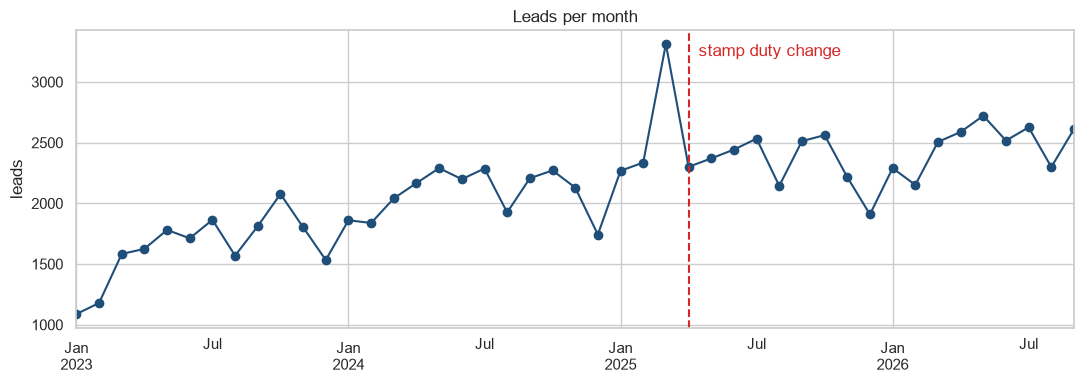

March 2025 vs February 2025: +42%   (README: about +40%)


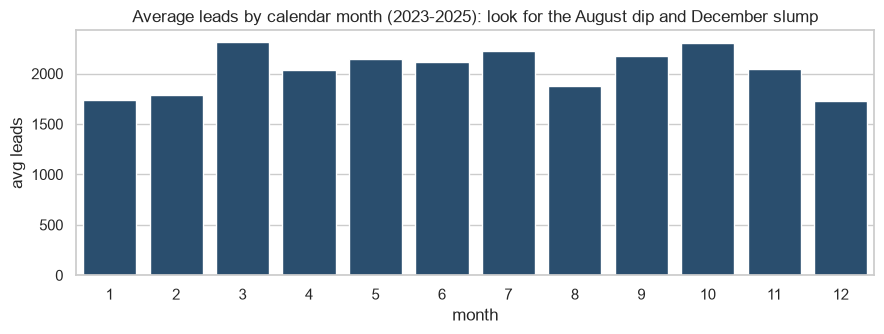

In [17]:
monthly = leads.groupby(leads["created_date"].dt.to_period("M").dt.to_timestamp()).size()

fig, ax = plt.subplots(figsize=(11, 4))
monthly.plot(ax=ax, marker="o", color="#1f4e79")
ax.axvline(pd.Timestamp("2025-04-01"), color="#d62728", linestyle="--")
ax.text(pd.Timestamp("2025-04-01"), monthly.max(), "  stamp duty change", color="#d62728", va="top")
ax.set(title="Leads per month", xlabel="", ylabel="leads")
plt.tight_layout(); plt.savefig(OUT / "leads_per_month.png", dpi=150); plt.show()

feb, mar = monthly.get(pd.Timestamp("2025-02-01")), monthly.get(pd.Timestamp("2025-03-01"))
if feb and mar:
    print(f"March 2025 vs February 2025: {(mar / feb - 1) * 100:+.0f}%   (README: about +40%)")
    checks["mar25_vs_feb25_leads_%"] = round((mar / feb - 1) * 100)

full_years = monthly[(monthly.index >= "2023-01-01") & (monthly.index <= "2025-12-01")]
by_moy = full_years.groupby(full_years.index.month).mean()
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.barplot(x=by_moy.index, y=by_moy.values, color="#1f4e79", ax=ax)
ax.set(title="Average leads by calendar month (2023-2025): look for the August dip and December slump", xlabel="month", ylabel="avg leads")
plt.tight_layout(); plt.savefig(OUT / "leads_by_calendar_month.png", dpi=150); plt.show()

### C2. Monthly completions by transaction type (**CONFIG**)
I could not see the `transactions` columns, so the date and type columns are guessed by name. Check what it picked.

In [18]:
tx = tables["transactions"].copy()
print(tx.dtypes.to_string())
date_cols = [c for c in tx.columns if re.search("date", c, re.I)]
type_cols = [c for c in tx.columns if re.search("type", c, re.I)]
COMPLETION_COL = next((c for c in date_cols if re.search("complet|exchange|start", c, re.I)), date_cols[0] if date_cols else None)
TYPE_COL = type_cols[0] if type_cols else None
print("\nDate columns:", date_cols, "-> using", COMPLETION_COL)
print("Type columns:", type_cols, "-> using", TYPE_COL)

transaction_id                    str
lead_id                           str
customer_id                       str
property_id                       str
transaction_type                  str
finance_type                   string
agreed_price_gbp                Int64
agreed_rent_pcm_gbp             Int64
discount_pct                  float64
contract_date                  object
completion_or_move_in_date     object
tenancy_months                  Int64
mortgage_ltv_pct              Float64
payment_currency                  str

Date columns: ['contract_date', 'completion_or_move_in_date'] -> using completion_or_move_in_date
Type columns: ['transaction_type', 'finance_type'] -> using transaction_type


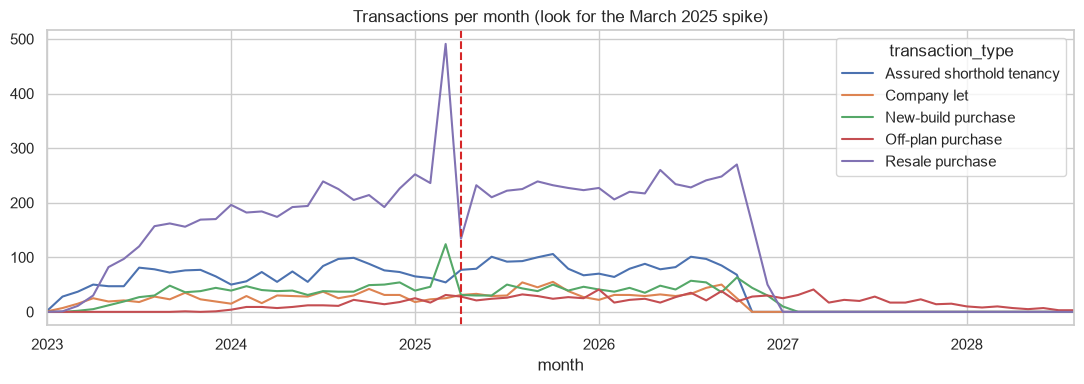

In [19]:
if COMPLETION_COL:
    tx[COMPLETION_COL] = pd.to_datetime(tx[COMPLETION_COL], errors="coerce")
    tx["month"] = tx[COMPLETION_COL].dt.to_period("M").dt.to_timestamp()
    pivot = (tx.groupby(["month", TYPE_COL]).size().unstack(fill_value=0) if TYPE_COL
             else tx.groupby("month").size().to_frame("transactions"))
    ax = pivot.plot(figsize=(11, 4), title="Transactions per month (look for the March 2025 spike)")
    ax.axvline(pd.Timestamp("2025-04-01"), color="#d62728", linestyle="--")
    plt.tight_layout(); plt.savefig(OUT / "transactions_per_month.png", dpi=150); plt.show()

### C3. Conversion by lead source (using the agreed 14-channel map)

,conversion_pct,closed_leads
source_clean,,
Relocation partner,38.8,1907
Branch walk-in,24.9,2896
Referral,20.1,5689
Email newsletter,19.6,5366
Rightmove,18.1,24093
Veltrix website,17.6,11754
OnTheMarket,17.3,4324
Zoopla,17.2,12245
Instagram,17.0,4141


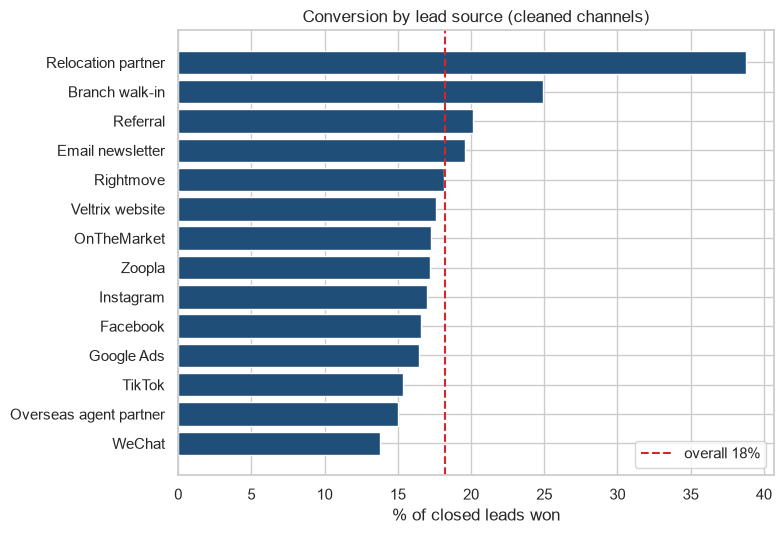

In [20]:
leads["source_clean"] = leads["lead_source"].map(LEAD_SOURCE_MAP)
assert leads["source_clean"].notna().all(), "Unmapped lead_source values: see A1b"
by_source = (leads[leads["closed"]].groupby("source_clean")["converted"]
             .agg(conversion_pct=lambda s: s.mean() * 100, closed_leads="size")
             .sort_values("conversion_pct", ascending=False))
display(by_source.round(1))

top = by_source.sort_values("conversion_pct")
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top["conversion_pct"], color="#1f4e79")
ax.axvline(overall_conv, color="#d62728", linestyle="--", label=f"overall {overall_conv:.0f}%")
ax.set(title="Conversion by lead source (cleaned channels)", xlabel="% of closed leads won")
ax.legend(); plt.tight_layout(); plt.savefig(OUT / "conversion_by_source.png", dpi=150); plt.show()

### C4. Conversion by agent seniority

,conversion_pct,closed_leads
seniority,,
Junior,12.6,32564
Mid,17.4,34566
Senior,26.9,24294


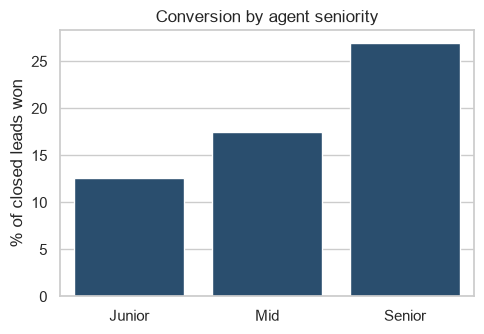

In [21]:
agents = tables["agents"]
la = leads.merge(agents[["agent_id", "seniority"]], on="agent_id", how="left")
by_sen = (la[la["closed"]].groupby("seniority")["converted"]
          .agg(conversion_pct=lambda s: s.mean() * 100, closed_leads="size"))
display(by_sen.round(1))
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(x=by_sen.index, y=by_sen["conversion_pct"], color="#1f4e79", ax=ax)
ax.set(title="Conversion by agent seniority", ylabel="% of closed leads won", xlabel="")
plt.tight_layout(); plt.savefig(OUT / "conversion_by_seniority.png", dpi=150); plt.show()

### C5. Conversion against first response time (**CONFIG**)
Response time is not a column in `leads`. The cell searches every table for a column with `respon` or `reply` in its name.
The README says the median response is about 74 minutes for senior agents and about 575 for juniors, so the units should be **minutes**.
Check that here before using the bands.

In [22]:
hits = [(t, c) for t, df in tables.items() for c in df.columns if re.search("respon|reply", c, re.I)]
print("Columns that look like response time:", hits)

Columns that look like response time: [('campaign_responses', 'response_id'), ('campaign_responses', 'response_type'), ('campaign_responses', 'response_time'), ('interactions', 'response_time_min')]


Using: interactions response_time_min

Median first reply by seniority (README: ~74 senior vs ~575 junior, in minutes):
seniority
Junior    234.0
Mid        90.0
Senior     27.0


,conversion_pct,closed_leads
first_reply,,
under 1h,31.0,32887
1-4h,14.8,36347
4-24h,5.3,20044
over 24h,0.6,1821


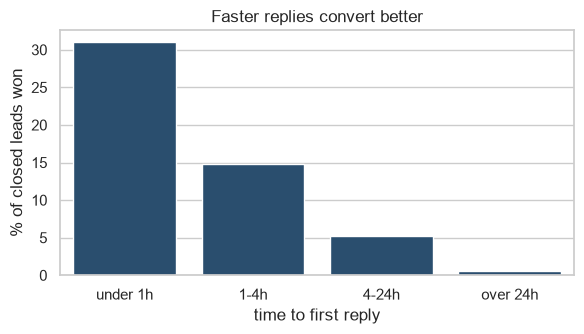


Conversion % by reply band AND seniority (if seniority gaps shrink inside a band, speed explains most of it):


seniority,Junior,Mid,Senior
band,,,
under 1h,27.2,29.8,32.2
1-4h,18.0,14.1,7.1
4-24h,6.1,3.3,2.1
over 24h,0.6,0.8,0.0


In [23]:
# CONFIG: set RESP_TABLE / RESP_COL by hand if the auto choice is wrong.
cand = [(t, c) for t, c in hits if "lead_id" in tables[t].columns and is_numeric_dtype(tables[t][c])]
RESP_TABLE, RESP_COL = cand[0] if cand else (None, None)
print("Using:", RESP_TABLE, RESP_COL)

if RESP_COL:
    per_lead = tables[RESP_TABLE].groupby("lead_id")[RESP_COL].min().rename("first_reply")
    lr = la.merge(per_lead, left_on="lead_id", right_index=True, how="left")
    print("\nMedian first reply by seniority (README: ~74 senior vs ~575 junior, in minutes):")
    print(lr.groupby("seniority")["first_reply"].median().round(0).to_string())

    bands = pd.cut(lr["first_reply"], [-np.inf, 60, 240, 1440, np.inf],
                   labels=["under 1h", "1-4h", "4-24h", "over 24h"])
    by_band = (lr[lr["closed"]].groupby(bands[lr["closed"]], observed=True)["converted"]
               .agg(conversion_pct=lambda s: s.mean() * 100, closed_leads="size"))
    display(by_band.round(1))
    fig, ax = plt.subplots(figsize=(6, 3.5))
    sns.barplot(x=by_band.index.astype(str), y=by_band["conversion_pct"], color="#1f4e79", ax=ax)
    ax.set(title="Faster replies convert better", ylabel="% of closed leads won", xlabel="time to first reply")
    plt.tight_layout(); plt.savefig(OUT / "conversion_by_reply_band.png", dpi=150); plt.show()

    # Senior agents reply faster AND convert better. Is it skill or speed? Compare within the same reply band.
    both = (lr[lr["closed"]].assign(band=bands[lr["closed"]])
            .groupby(["band", "seniority"], observed=True)["converted"].mean().unstack() * 100)
    print("\nConversion % by reply band AND seniority (if seniority gaps shrink inside a band, speed explains most of it):")
    display(both.round(1))
    srv = lr.groupby("seniority")["first_reply"].median()
    checks["median_reply_min_senior"] = srv.get("Senior")
    checks["median_reply_min_junior"] = srv.get("Junior")
else:
    print("No usable response-time column found. Paste the output of the cell above and I will adjust.")

### C6. Browsing behaviour: overseas share, night-time sessions, device mix
Night-time = sessions starting between 00:00 and 06:00. This assumes `session_start` is already UK local time. Confirm that in the data dictionary.

,sessions,overseas_pct,night_pct,mobile_pct
0,2003460,9.2,4.6,61.5


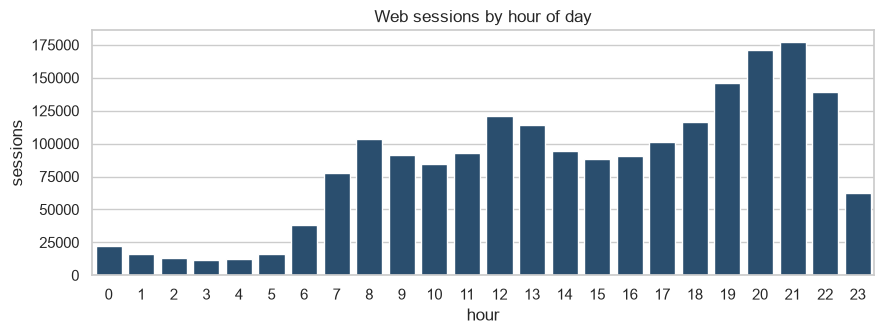

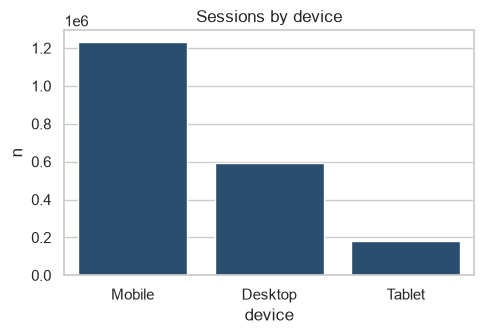

In [24]:
beh = con.sql('''
    SELECT
      COUNT(*)                                                                    AS sessions,
      ROUND(100.0 * AVG(CASE WHEN ip_country <> 'GB' THEN 1 ELSE 0 END), 1)      AS overseas_pct,
      ROUND(100.0 * AVG(CASE WHEN EXTRACT(hour FROM CAST(session_start AS TIMESTAMP)) < 6 THEN 1 ELSE 0 END), 1) AS night_pct,
      ROUND(100.0 * AVG(CASE WHEN device = 'Mobile' THEN 1 ELSE 0 END), 1)       AS mobile_pct
    FROM web_sessions
''').df()
display(beh)

hourly = con.sql('''
    SELECT EXTRACT(hour FROM CAST(session_start AS TIMESTAMP)) AS hour, COUNT(*) AS sessions
    FROM web_sessions GROUP BY 1 ORDER BY 1
''').df()
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.barplot(data=hourly, x="hour", y="sessions", color="#1f4e79", ax=ax)
ax.set(title="Web sessions by hour of day")
plt.tight_layout(); plt.savefig(OUT / "sessions_by_hour.png", dpi=150); plt.show()

dev = con.sql("SELECT device, COUNT(*) AS n FROM web_sessions GROUP BY 1 ORDER BY 2 DESC").df()
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(data=dev, x="device", y="n", color="#1f4e79", ax=ax)
ax.set(title="Sessions by device")
plt.tight_layout(); plt.savefig(OUT / "sessions_by_device.png", dpi=150); plt.show()

### C7. Virtual tours (`site_visits.visit_type = 'Virtual'`)
Leads that took a virtual visit may convert differently, but this is a correlation: leads that visit at all are already more engaged.

In [25]:
display(con.sql("SELECT visit_type, COUNT(*) AS n, ROUND(100.0*COUNT(*)/SUM(COUNT(*)) OVER (), 1) AS pct FROM site_visits GROUP BY 1 ORDER BY 2 DESC").df())

virt = con.sql('''
    SELECT l.converted, (v.lead_id IS NOT NULL) AS had_virtual_visit
    FROM leads l
    LEFT JOIN (SELECT DISTINCT lead_id FROM site_visits WHERE visit_type = 'Virtual') v USING (lead_id)
    WHERE l.lead_stage IN ('Won', 'Lost')
''').df()
print("Conversion % of closed leads, by whether the lead had a virtual visit:")
print((virt.groupby("had_virtual_visit")["converted"].agg(["mean", "size"]).assign(mean=lambda d: (d["mean"] * 100).round(1))).rename(columns={"mean": "conversion_%", "size": "closed_leads"}).to_string())

,visit_type,n,pct
0,In person,166554,71.3
1,Virtual,34241,14.7
2,Open house,20797,8.9
3,Proxy (family or solicitor),12001,5.1


Conversion % of closed leads, by whether the lead had a virtual visit:
                   conversion_%  closed_leads
had_virtual_visit                            
False                      14.2         66418
True                       29.0         25006


## D. Sanity check: what I found vs what the README says to expect
Anything far from the README is either a bug in my cell or a data-quality finding. Both are worth knowing about.

In [26]:
expected = {
    "duplicate_%": "about 2",
    "conversion_closed_%": "about 18",
    "open_leads_%": "about 4.5",
    "mar25_vs_feb25_leads_%": "about +40",
    "median_reply_min_senior": "about 74",
    "median_reply_min_junior": "about 575",
    "anonymous_sessions_%": "about 25",
}
summary = pd.DataFrame({"found": pd.Series(checks), "README expects": pd.Series(expected)})
display(summary)

,found,README expects
anonymous_sessions_%,25.00,about 25
conversion_closed_%,18.20,about 18
duplicate_%,1.40,about 2
duplicate_records,1427.00,NaN
mar25_vs_feb25_leads_%,42.00,about +40
median_reply_min_junior,234.00,about 575
median_reply_min_senior,27.00,about 74
open_leads_%,4.60,about 4.5
typo_rate_stated_budget_gbp_%,0.45,NaN
typo_rate_stated_rent_budget_pcm_gbp_%,0.41,NaN


## Hand-off notes
- `outputs/duplicate_customer_map.csv`: duplicate -> survivor mapping for the DA team (Day 4).
- `outputs/*.png`: charts for the EDA deck (Day 5).
- `cleaning_maps.py`: the lead-source and country maps, used by `03_cleaning.ipynb`.
- Next: `03_cleaning.ipynb`, then the feature work (Days 6-7).

In [27]:
  old = pd.read_csv(OUT/"duplicate_customer_map_old.csv"); new = pd.read_csv(OUT/"duplicate_customer_map.csv")
  print(len(set(zip(old.duplicate_id, old.survivor_id)) & set(zip(new.duplicate_id, new.survivor_id))), "identical pairs of", len(new))

1427 identical pairs of 1427


In [28]:
inter = tables["interactions"].merge(tables["agents"][["agent_id","seniority"]], on="agent_id", how="left")
print(inter.groupby("seniority")["response_time_min"].median().round(0))

seniority
Junior    466.0
Mid       178.0
Senior     54.0
Name: response_time_min, dtype: Float64
